# Introduction

This notebook continues the work from churn_data.ipynb, which handled the exploratory data analysis and the first preprocessing step. That step dropped 13 columns that either carried no predictive value (like CustomerID) or introduced data leakage (like Churn Score and Churn Reason), based on the exclusions set out in the proposal.

The output of that notebook, cleaned_churn_data.csv, is the starting point here. It still has the 11 blank Total Charges values and all the categorical columns as text, since fixing those now happens after the train and test split. This keeps the median used for imputation and the categories learned during encoding based only on the training data, avoiding the data leakage flagged during supervisor feedback.

This notebook covers the remaining preprocessing, class imbalance handling with SMOTE, training and tuning three models `(Logistic Regression, Random Forest, and LightGBM)`, evaluating them, and applying SHAP to the best performing model.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("cleaned_churn_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1


# Step 1: Convert Total Charges to a Number

Total Charges is currently stored as text, and the 11 missing values are blank spaces rather than true empty cells. This step converts the column to a numeric type, turning those blanks into proper missing values (NaN) so they can be handled correctly later. The values are not filled in yet, that happens after the train and test split, using only the training data.

In [2]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
print("Missing Total Charges after conversion:", df["Total Charges"].isna().sum())
df["Total Charges"].dtype

Missing Total Charges after conversion: 11


dtype('float64')

# Step 2: Train and Test Split

The dataset is split into training and test sets before any imputation, encoding, or scaling happens. This is the key step for avoiding data leakage, everything that comes after (filling in Total Charges, encoding categories, scaling, SMOTE) will be fit only on the training data, then applied to the test data using that same fit. The test set stays untouched until final evaluation.

A stratified 80/20 split is used, with a fixed random seed of 42 for reproducibility. Stratifying on Churn Value keeps the same churn rate (about 26.5%) in both the training and test sets, rather than letting one set end up with a disproportionate number of churners by chance.

In [3]:
X = df.drop(columns=["Churn Value"])
y = df["Churn Value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print()
print("Churn rate in training set:", y_train.mean().round(4))
print("Churn rate in test set:", y_test.mean().round(4))

Training set shape: (5634, 19)
Test set shape: (1409, 19)

Churn rate in training set: 0.2654
Churn rate in test set: 0.2654


# Step 3: Preprocessing Pipeline

This step handles the missing Total Charges values, encodes the categorical columns, and scales the numeric columns, all in one pipeline. The pipeline is fit only on the training data, then used to transform both the training and test data. This means the median used to fill in Total Charges, the categories the encoders learn, and the scaling parameters are all worked out from training data alone, matching the approach used by Sana et al. (2022) for this dataset and avoiding data leakage.

The columns are grouped by how they need to be handled:

- Numeric columns (Tenure Months, Monthly Charges, Total Charges) get the missing values filled with the median, then get scaled using StandardScaler. Scaling matters most for Logistic Regression, since it is sensitive to features being on different numeric scales, but it is applied to all three numeric columns regardless of which model uses them.
- Binary columns (Gender, Senior Citizen, Partner, Dependents, Phone Service, Paperless Billing) only have two categories each, so they are label encoded into 0 and 1.
- Multi category columns (Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies, Contract, Payment Method) are one hot encoded, since they have three or more categories and label encoding would wrongly imply an order between them.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

numeric_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
binary_cols = ["Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Paperless Billing"]
multi_cols = [
    "Multiple Lines", "Internet Service", "Online Security", "Online Backup",
    "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Payment Method"
]

numeric_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

binary_pipeline = Pipeline(steps=[
    ("encode", OrdinalEncoder())
])

multi_pipeline = Pipeline(steps=[
    ("encode", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("bin", binary_pipeline, binary_cols),
    ("multi", multi_pipeline, multi_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print("Training set shape after preprocessing:", X_train_processed.shape)
print("Test set shape after preprocessing:", X_test_processed.shape)
X_train_processed.head()

Training set shape after preprocessing: (5634, 30)
Test set shape after preprocessing: (1409, 30)


,num__Tenure Months,num__Monthly Charges,num__Total Charges,bin__Gender,bin__Senior Citizen,bin__Partner,bin__Dependents,bin__Phone Service,bin__Paperless Billing,multi__Multiple Lines_No phone service,...,multi__Tech Support_Yes,multi__Streaming TV_No internet service,multi__Streaming TV_Yes,multi__Streaming Movies_No internet service,multi__Streaming Movies_Yes,multi__Contract_One year,multi__Contract_Two year,multi__Payment Method_Credit card (automatic),multi__Payment Method_Electronic check,multi__Payment Method_Mailed check
4626,0.102371,-0.521976,-0.263290,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4192,-0.711743,0.337478,-0.504815,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5457,-0.793155,-0.809013,-0.751214,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4717,-0.263980,0.284384,-0.173700,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
4673,-1.281624,-0.676279,-0.990851,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# Step 4: Handling Class Imbalance with SMOTE


The training set has a churn rate of about 26.5%, meaning churned customers are a minority. Left as is, this tends to bias models toward the majority class, giving misleadingly high accuracy while missing most actual churners, exactly the risk highlighted by Suguna et al. (2025).

SMOTE is applied here to fix that. It works by creating synthetic examples of the minority class based on existing churned customers, rather than just duplicating rows. Following Bilal et al. (2022), SMOTE is applied only to the training set, after the split and after encoding. The test set is left with its original, real world class distribution, since that is what the model needs to be evaluated against.

In [8]:
%pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print()
print("After SMOTE:")
print(y_train_resampled.value_counts())

  Obtaining dependency information for imbalanced-learn from https://files.pythonhosted.org/packages/91/54/760ccac7d8feeea0c191767a6b025d3ca5014084443ff48afb6fb24ef056/imbalanced_learn-0.14.2-py3-none-any.whl.metadata
  Obtaining dependency information for sklearn-compat<0.2,>=0.1.6 from https://files.pythonhosted.org/packages/b0/20/47a7e947757008be1b77f1c6a6861d26a84ef4b4ea3e6ebf4eff24f24d5d/sklearn_compat-0.1.6-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/236.1 kB ? eta -:--:--
   ----- --------------------------------- 30.7/236.1 kB 435.7 kB/s eta 0:00:01
   ------ -------------------------------- 41.0/236.1 kB 326.8 kB/s eta 0:00:01
   ---------- ---------------------------- 61.4/236.1 kB 326.1 kB/s eta 0:00:01
   ------------- ------------------------- 81.9/236.1 kB 381.3 kB/s eta 0:00:01
   --------------- ----


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Before SMOTE:
Churn Value
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn Value
0    4139
1    4139
Name: count, dtype: int64


# Step 5: Model Training and Hyperparameter Tuning


Three models are trained here: Logistic Regression, Random Forest, and LightGBM. Each one goes through a 5 fold cross validated grid search on the training set, so the hyperparameters are chosen using only training data, keeping the test set fully held out for final evaluation. F1-score is used as the scoring metric for the grid search, since it balances precision and recall and is one of the two primary metrics named in the research question.

A fixed random seed of 42 is used throughout, matching the proposal's design choice for reproducibility.

In [11]:
%pip install lightgbm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

# Logistic Regression
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["lbfgs"],
    "max_iter": [1000]
}
lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    lr_param_grid, cv=5, scoring="f1", n_jobs=-1
)
lr_grid.fit(X_train_resampled, y_train_resampled)

# Random Forest
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid, cv=5, scoring="f1", n_jobs=-1
)
rf_grid.fit(X_train_resampled, y_train_resampled)

# LightGBM
lgbm_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [-1, 10],
    "learning_rate": [0.05, 0.1],
    "num_leaves": [31, 50]
}
lgbm_grid = GridSearchCV(
    LGBMClassifier(random_state=42, verbose=-1),
    lgbm_param_grid, cv=5, scoring="f1", n_jobs=-1
)
lgbm_grid.fit(X_train_resampled, y_train_resampled)

print("Best Logistic Regression params:", lr_grid.best_params_)
print("Best Logistic Regression F1 (CV):", round(lr_grid.best_score_, 4))
print()
print("Best Random Forest params:", rf_grid.best_params_)
print("Best Random Forest F1 (CV):", round(rf_grid.best_score_, 4))
print()
print("Best LightGBM params:", lgbm_grid.best_params_)
print("Best LightGBM F1 (CV):", round(lgbm_grid.best_score_, 4))

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Best Logistic Regression params: {'C': 10, 'max_iter': 1000, 'solver': 'lbfgs'}
Best Logistic Regression F1 (CV): 0.7893

Best Random Forest params: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Best Random Forest F1 (CV): 0.86

Best LightGBM params: {'learning_rate': 0.05, 'max_depth': 10, 'n_estimators': 100, 'num_leaves': 50}
Best LightGBM F1 (CV): 0.8444


# Step 6: Model Evaluation on the Test Set


Each tuned model is now evaluated once on the test set, which has been held out from every step so far, no imputation, encoding, scaling, or SMOTE parameters were learned from it. Accuracy, precision, recall, F1-score, and AUC-ROC are calculated for all three models, with F1-score and AUC-ROC treated as the primary metrics for comparison, since the dataset is imbalanced and accuracy alone can be misleading.

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "LightGBM": lgbm_grid.best_estimator_
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_proba

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.7438,0.5115,0.7754,0.6164,0.8466
Random Forest,0.7885,0.5969,0.6257,0.6110,0.8375
LightGBM,0.7857,0.5870,0.6497,0.6168,0.8488


## Interpretation:

All three models perform similarly on the test set, with F1-scores between 0.61 and 0.62. LightGBM has the highest F1-score (0.6168) and the highest AUC-ROC (0.8488), narrowly ahead of Logistic Regression (F1 0.6164, AUC-ROC 0.8466) and Random Forest (F1 0.6110, AUC-ROC 0.8375). Given how close these values are, this is a marginal difference rather than a clear separation between models.

The cross-validation F1-scores during grid search were considerably higher (0.79 to 0.86) than the test set F1-scores shown here. This is because cross-validation was performed on the SMOTE-resampled training data, which is artificially balanced, making the classification task appear easier than it is on the real, imbalanced test set. The test set results are the reliable measure of how these models would perform in practice.

Logistic Regression shows a noticeably higher recall (0.7754) than Random Forest (0.6257) or LightGBM (0.6497), meaning it identifies more actual churners, but at the cost of lower precision (0.5115), producing more false positives. This is a common trade off, and the right balance depends on whether the business priority is catching as many at risk customers as possible or minimising wasted retention effort on customers who were not actually going to churn.

# Step 7: Confusion Matrices

A confusion matrix breaks down each model's predictions into correct and incorrect calls for both classes, giving a clearer picture than a single accuracy number. This matters here specifically because of the class imbalance, it shows directly how many actual churners each model catches versus misses, rather than hiding that behind an overall accuracy figure.

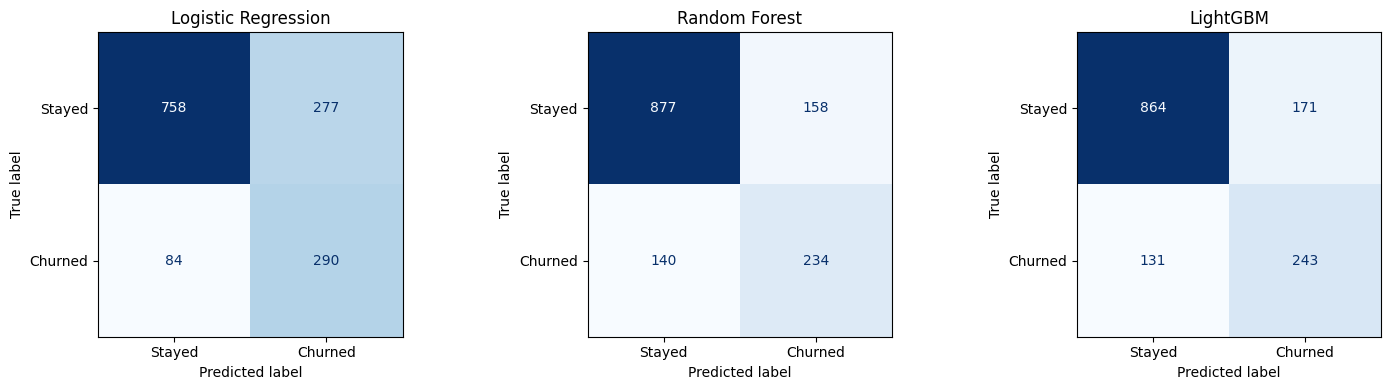

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm_display = ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Stayed", "Churned"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig("Diagrams/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Step 8: ROC Curves

The ROC curve plots true positive rate against false positive rate across every possible classification threshold, and AUC-ROC is the area under that curve. Plotting all three models on the same chart makes it easy to see that they overlap closely, consistent with how close their AUC-ROC scores were in the results table.

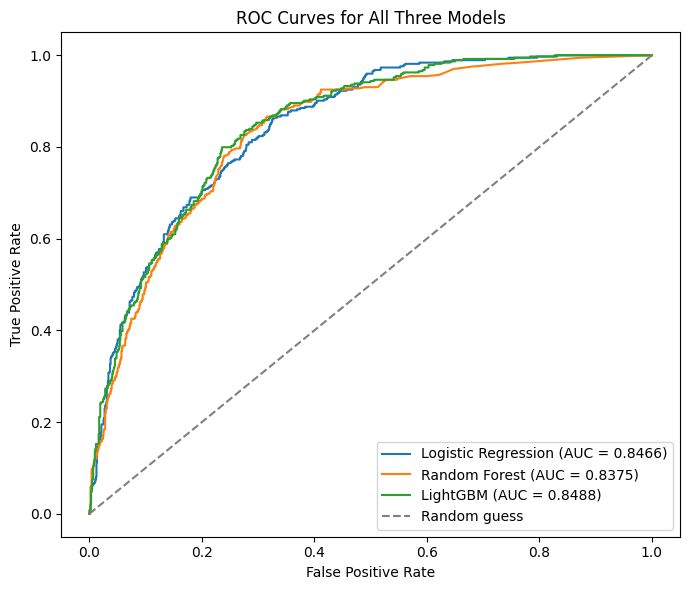

In [14]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for name, y_proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All Three Models")
plt.legend()
plt.tight_layout()
plt.savefig("Diagrams/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Step 9: SHAP Analysis

SHAP values explain individual predictions by showing how much each feature pushed a prediction toward or away from churn, rather than just ranking features by an internal model score. This is applied only to LightGBM, the best performing model on the test set, following the same approach as Sinaga and Widianto (2023) and Peng and Peng (2022), who both used SHAP to identify churn drivers after model comparison rather than applying it to every model tested.

  Obtaining dependency information for shap from https://files.pythonhosted.org/packages/a5/8e/cee1ee136a4e54fe2fbb63a60d72d7c25e21a4ffe6aa05779cab7669cb31/shap-0.51.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for slicer==0.0.8 from https://files.pythonhosted.org/packages/63/81/9ef641ff4e12cbcca30e54e72fb0951a2ba195d0cda0ba4100e532d929db/slicer-0.0.8-py3-none-any.whl.metadata
  Obtaining dependency information for numba from https://files.pythonhosted.org/packages/26/4d/23dab7f4233be0fc34f54a169ed85238467cd24d8adf2498e5c12ea19dc7/numba-0.67.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for llvmlite from https://files.pythonhosted.org/packages/7d/49/47cd23e05d52d117b6119871ec299adedc9d8d332a2296964d9b2adc06d9/llvmlite-0.49.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for cloudpickle from https://files.pythonhosted.org/packages/88/39/799be3f2f0f38cc727ee3b4f1445fe6d5e4133064ec2e4115069418a5bb6/cloudpickle-3.


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\saihi\AppData\Local\Programs\Python\Python311\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


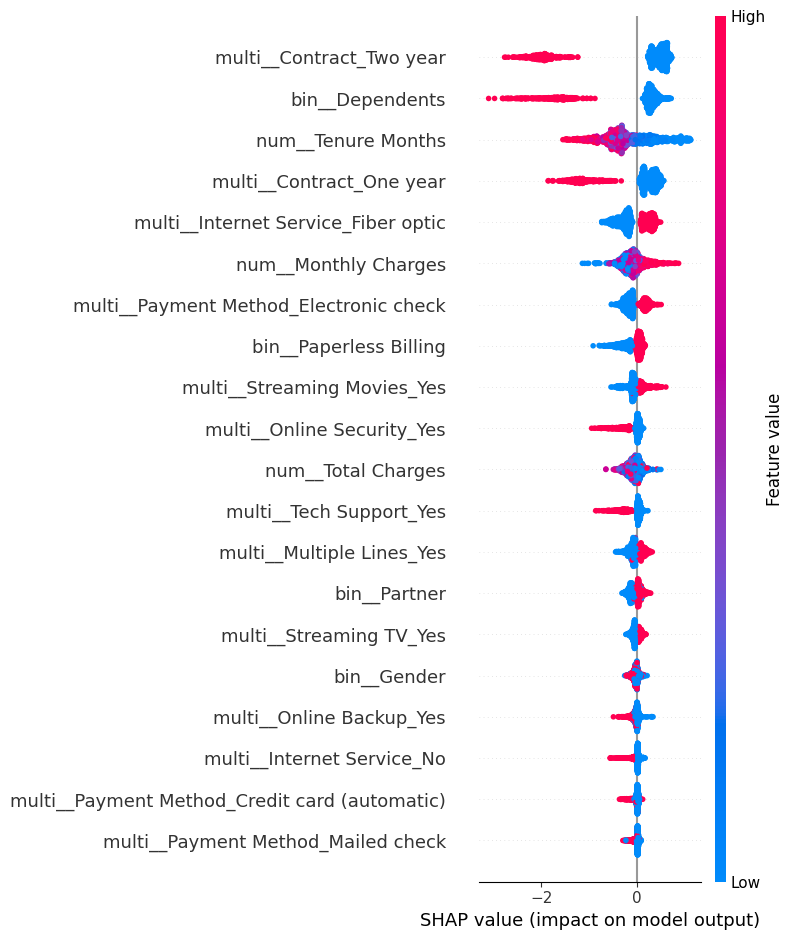

In [16]:
%pip install shap
import shap

explainer = shap.TreeExplainer(lgbm_grid.best_estimator_)
shap_values = explainer.shap_values(X_test_processed)

# Some versions of SHAP return a list, one array per class, for binary classifiers.
# When that happens, index 1 is used since that's the churn class.
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(shap_values, X_test_processed, show=False)
plt.tight_layout()
plt.savefig("Diagrams/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

## Interpretation:

The SHAP summary plot shows how each feature affects individual churn predictions for the LightGBM model, rather than just ranking features by an overall importance score. Each dot is one customer from the test set, its horizontal position shows how much that feature pushed the prediction toward churn (right side) or toward staying (left side) for that customer, and its color shows whether that customer had a high (red) or low (blue) value for that feature.

Contract type dominates the plot. Customers with a two year contract (red dots on Contract_Two year) are pushed strongly toward staying, while customers without one (blue dots) are pushed toward churn. The same pattern holds for Contract_One year, having any fixed term contract lowers predicted churn risk, leaving month to month customers as the group the model associates with the highest risk. This matches Sinaga and Widianto (2023) and Peng and Peng (2022), who both identified contract type as one of the strongest churn predictors using SHAP on this same dataset.

Tenure Months shows a similar direction but with more spread, since it is a continuous number rather than a yes or no feature. Longer tenure (red) mostly pushes toward staying, and shorter tenure (blue) mostly pushes toward churning, though the effect size varies more smoothly across customers than the sharp two group split seen with contract type. This is consistent with tenure being identified alongside contract type as a leading predictor in the same two studies.

Dependents follows the same pattern as contract type, customers with dependents (red) are pushed toward staying, while customers without (blue) are pushed toward churn.

A few features push in the opposite direction. Internet Service_Fiber optic shows red dots (customers with fiber optic internet) sitting on the churn side, while blue dots (customers without it) sit toward staying. Monthly Charges shows a similar pattern, higher charges (red) tend to push slightly toward churn, and lower charges (blue) push slightly toward staying. Payment Method_Electronic check shows the same direction, customers who pay by electronic check are pushed toward churn more than those who do not.

Overall, the SHAP results point to contract type and tenure as the two strongest drivers of predicted churn, with the type of internet service, monthly charges, and payment method contributing smaller, secondary effects. This aligns with the model's own numeric performance and with the existing literature this study builds on.

# Conclusion

This notebook set out to answer how Logistic Regression, Random Forest, and LightGBM compare for predicting customer churn on the Telco dataset, using F1-score and AUC-ROC as the primary metrics.

On SRQ1, which model performs best, LightGBM narrowly came out on top on both primary metrics (F1 0.6168, AUC-ROC 0.8488), just ahead of Logistic Regression (F1 0.6164, AUC-ROC 0.8466) and Random Forest (F1 0.6110, AUC-ROC 0.8375). The gap between all three is small enough that this is closer to a three way tie than a clear winner, though LightGBM's edge is consistent with what Bogaert and Delaere (2023) found when comparing gradient boosting against other ensemble methods.

On SRQ2, which features contribute most to predicting churn, the SHAP analysis on LightGBM identified contract type and tenure as the two strongest drivers, with customers on month to month contracts and shorter tenure being pushed most strongly toward a churn prediction. This matches Sinaga and Widianto (2023) and Peng and Peng (2022), who both identified the same two features as leading predictors using SHAP on this dataset. Internet service type, monthly charges, and payment method showed smaller, secondary effects.

On SRQ3, how preprocessing and class imbalance handling influenced performance, the leakage safe restructuring, splitting before imputation, encoding, and scaling, meant every reported test set result reflects genuinely unseen data. SMOTE, applied only to the training set following Bilal et al. (2022), corrected the training class balance without touching the test set. This mattered directly for interpreting the results, cross validation F1-scores during grid search (0.79 to 0.86) were noticeably higher than the true test set F1-scores (0.61 to 0.62), since cross validation ran on the artificially balanced, SMOTE resampled training data. This gap is itself a finding worth reporting, it shows why evaluating only on a held out, realistically imbalanced test set matters, rather than trusting scores from resampled data.

Overall, this study did not find one model to be decisively superior for this dataset, but it did find a consistent set of churn drivers across model performance and feature attribution, and it produced a reproducible, leakage aware pipeline consistent with the standardisation gap identified by Geiler et al. (2022) in the wider literature.

# Reference List

Bilal, S.F., Almazroi, A.A. and Bashir, S., 2022. An ensemble based approach using a combination of clustering and classification algorithms to enhance customer churn prediction in telecom industry. PeerJ Computer Science, 8, p.e854. Available at: https://peerj.com/articles/cs-854/. Accessed on: 11/06/2026

Peng, K. and Peng, Y., 2022. Research on telecom customer churn prediction based on GA-XGBoost and SHAP. Journal of Computer and Communications, 10(1), pp.107–120. Available at: https://www.scirp.org/journal/paperinformation?paperid=121175. Accessed on: 11/06/2026

Sana, J.K., Abedin, M.Z., Rahman, M.S. and Rahman, M.S., 2022. A novel customer churn prediction model for the telecommunication industry using data transformation methods and feature selection. PLOS ONE, 17(12), p.e0278095. Available at: https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0278095. Accessed on: 11/06/2026

Sinaga, R. and Widianto, S., 2023. Understanding telecommunication customer churn: insights from LightGBM predictive modelling and SHAP feature interpretation. ASEAN Marketing Journal, 15(1), article 4. Available at: https://scholarhub.ui.ac.id/amj/vol15/iss1/4/. Accessed on: 11/06/2026

Suguna, R. et al., 2025. Mitigating class imbalance in churn prediction with ensemble methods and SMOTE. Scientific Reports, 15(1), p.16256. Available at: https://doi.org/10.1038/s41598-025-01031-0. Accessed on: 11/06/2026